In [82]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import Subset, DataLoader

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

from collections import Counter
import seaborn as sns


In [83]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if device.type == "cuda":
    print("GPU Name:", torch.cuda.get_device_name(0))

Device: cpu


- 64x64 is the native, original resolution of the images in the EuroSAT dataset.
- The parameters in the Normalize are the calculated channel means and std deviations of the ImageNet dataset.

In [ ]:
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    # transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [85]:
eurosat_dataset_rgb = datasets.EuroSAT(root="../data", download=True, transform=transform)

In [86]:
print(eurosat_dataset_rgb)

Dataset EuroSAT
    Number of datapoints: 27000
    Root location: ../data
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
               Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
           )


In [87]:
print(eurosat_dataset_rgb.class_to_idx)

{'AnnualCrop': 0, 'Forest': 1, 'HerbaceousVegetation': 2, 'Highway': 3, 'Industrial': 4, 'Pasture': 5, 'PermanentCrop': 6, 'Residential': 7, 'River': 8, 'SeaLake': 9}


In [88]:
print(dir(eurosat_dataset_rgb))

['__add__', '__annotate_func__', '__annotations_cache__', '__class__', '__class_getitem__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__len__', '__lt__', '__module__', '__ne__', '__new__', '__orig_bases__', '__parameters__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', '_base_folder', '_check_exists', '_data_folder', '_format_transform_repr', '_repr_indent', 'class_to_idx', 'classes', 'download', 'extensions', 'extra_repr', 'find_classes', 'imgs', 'loader', 'make_dataset', 'root', 'samples', 'target_transform', 'targets', 'transform', 'transforms']


In [89]:
print([a for a in dir(eurosat_dataset_rgb) if not a.startswith("_")])

['class_to_idx', 'classes', 'download', 'extensions', 'extra_repr', 'find_classes', 'imgs', 'loader', 'make_dataset', 'root', 'samples', 'target_transform', 'targets', 'transform', 'transforms']


Stratified splitting

- Extract labels.
- Split off training.
- Equal split between test and val

In [90]:


targets = np.array(eurosat_dataset_rgb.targets)
train_indices, temp_indices, _, temp_targets = train_test_split(
    np.arange(len(targets)), targets, test_size = 0.2, stratify = targets, random_state = 50)
val_indices, test_indices = train_test_split(temp_indices, test_size = 0.5, stratify = temp_targets, random_state = 30)
train_dataset = Subset(eurosat_dataset_rgb, train_indices)
val_dataset = Subset(eurosat_dataset_rgb, val_indices)
test_dataset = Subset(eurosat_dataset_rgb, test_indices)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)


Class balance check

{'AnnualCrop': 0, 'Forest': 1, 'HerbaceousVegetation': 2, 'Highway': 3, 'Industrial': 4, 'Pasture': 5, 'PermanentCrop': 6, 'Residential': 7, 'River': 8, 'SeaLake': 9}
Class: AnnualCrop, Class Id: 0, Count: 3000, Percentage: 11.11%
Class: Forest, Class Id: 1, Count: 3000, Percentage: 11.11%
Class: HerbaceousVegetation, Class Id: 2, Count: 3000, Percentage: 11.11%
Class: Highway, Class Id: 3, Count: 2500, Percentage: 9.26%
Class: Industrial, Class Id: 4, Count: 2500, Percentage: 9.26%
Class: Pasture, Class Id: 5, Count: 2000, Percentage: 7.41%
Class: PermanentCrop, Class Id: 6, Count: 2500, Percentage: 9.26%
Class: Residential, Class Id: 7, Count: 3000, Percentage: 11.11%
Class: River, Class Id: 8, Count: 2500, Percentage: 9.26%
Class: SeaLake, Class Id: 9, Count: 3000, Percentage: 11.11%


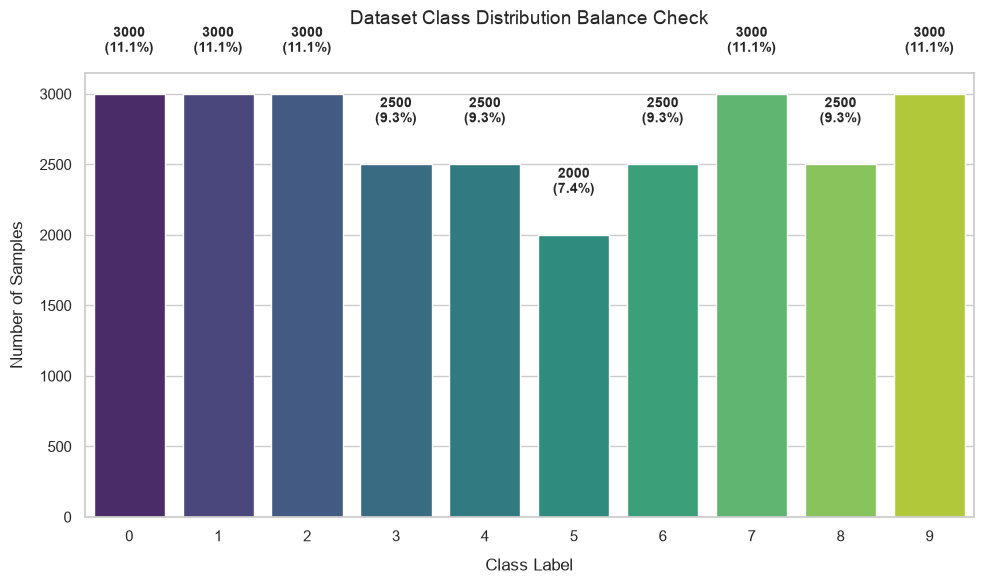

In [91]:

targets = np.array(eurosat_dataset_rgb.targets)
counter = Counter(targets)
total_samples = len(targets)
print(eurosat_dataset_rgb.class_to_idx)

for class_id, count in sorted(counter.items()):
    class_name = eurosat_dataset_rgb.classes[class_id]
    percentage = (count / total_samples) * 100
    print(f"Class: {class_name}, Class Id: {class_id}, Count: {count}, Percentage: {percentage:.2f}%")

classes = sorted(list(counter.keys()))
counts = [counter[c] for c in classes]
percentages = [(count / total_samples) * 100 for count in counts]

# 3. Plot the distribution
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

string_classes = [f"{c}" for c in classes]
ax = sns.barplot(x=string_classes, y=counts, palette="viridis")

for i, p in enumerate(ax.patches):
    height = p.get_height()
    ax.text(
        p.get_x() + p.get_width() / 2.0,
        height + (total_samples * 0.01),  # Dynamic offset above the bar
        f"{int(height)}\n({percentages[i]:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.title("Dataset Class Distribution Balance Check", fontsize=14, pad=35)
plt.xlabel("Class Label", fontsize=12, labelpad=10)
plt.ylabel("Number of Samples", fontsize=12, labelpad=10)
plt.tight_layout()
plt.show()



In [92]:
train_labels = targets[train_dataset.indices]
val_labels = targets[val_dataset.indices]
test_labels = targets[test_dataset.indices]

In [93]:
counters = {
    "orig": Counter(targets),
    "train": Counter(train_labels),
    "test": Counter(test_labels),
    "val": Counter(val_labels)
}

totals = {
    "orig": len(targets),
    "train": len(train_labels),
    "test": len(test_labels),
    "val": len(val_labels)
}

In [94]:
print(f"{'Class':<6} | {'Original_percent':<16} | {'train_percent':<13} | {'test_percent':<12} | {'val_percent':<11}")
print("-" * 71)

all_classes = sorted(list(counters["orig"].keys()))

for cls in all_classes:
    orig_pct  = (counters["orig"][cls]  / totals["orig"])  * 100
    train_pct = (counters["train"][cls] / totals["train"]) * 100
    test_pct  = (counters["test"][cls]  / totals["test"])  * 100
    val_pct   = (counters["val"][cls]   / totals["val"])   * 100
    
    # print(f"{cls:<6} | {orig_pct:.2f}%{' ':<10} | {train_pct:.2f}%{' ':<7} | {test_pct:.2f}%{' ':<6} | {val_pct:.2f}%")
    print(f"{cls:<6} | {orig_pct:7.2f}%         | {train_pct:6.2f}%       | {test_pct:6.2f}%      | {val_pct:6.2f}%")

Class  | Original_percent | train_percent | test_percent | val_percent
-----------------------------------------------------------------------
0      |   11.11%         |  11.11%       |  11.11%      |  11.11%
1      |   11.11%         |  11.11%       |  11.11%      |  11.11%
2      |   11.11%         |  11.11%       |  11.11%      |  11.11%
3      |    9.26%         |   9.26%       |   9.26%      |   9.26%
4      |    9.26%         |   9.26%       |   9.26%      |   9.26%
5      |    7.41%         |   7.41%       |   7.41%      |   7.41%
6      |    9.26%         |   9.26%       |   9.26%      |   9.26%
7      |   11.11%         |  11.11%       |  11.11%      |  11.11%
8      |    9.26%         |   9.26%       |   9.26%      |   9.26%
9      |   11.11%         |  11.11%       |  11.11%      |  11.11%


In [95]:
images, labels = next(iter(test_loader))
print(images.shape)          # expect [32, 3, 64, 64]
print(labels.shape)          # expect [32]
print(images.min(), images.max())
print(labels[:8])

torch.Size([32, 3, 64, 64])
torch.Size([32])
tensor(-1.7754) tensor(2.6400)
tensor([7, 0, 8, 2, 2, 9, 2, 0])


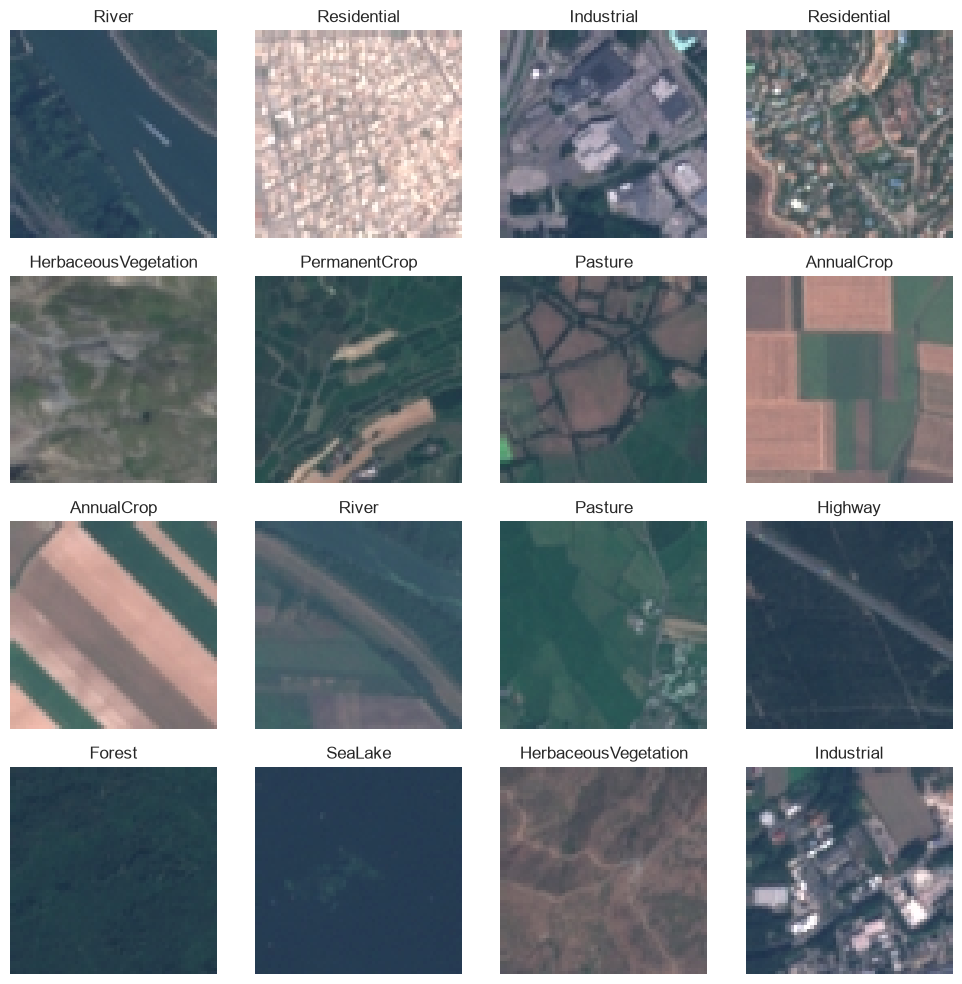

In [ ]:
import matplotlib.pyplot as plt

# Grab one batch
images, labels = next(iter(train_loader))

# Class names for titles
class_names = eurosat_dataset_rgb.classes

# Plot a grid of images
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
axes = axes.flatten()
# mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
# std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


for i, ax in enumerate(axes):
    # [C, H, W] → [H, W, C]
    img = images[i].permute(1, 2, 0).numpy()
    # img = (images[i] * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
    ax.imshow(img)
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()